<img src="logo.png" alt="Vegeta" width="240">

# Svarog-guard — a stray kilowatt at 20 m against the barriers

The 1 kW welding laser of notebook 48 and the guard that must contain its stray beam. The beam cases at 20 m from the
head (the raw collimated beam — the full power in a beam that stays small —, the beam diverging past the focus, a keyhole
back-reflection), eleven barriers (black, clear and laser-grade polycarbonate at 5 and 10 mm, a 65 mm brick, aluminium at
1.5 and 3 mm, mild steel at 1.5 and 3 mm), and the verdict per IEC 60825-4 exposure class (T1 10 s, T2 100 s, T3 30 000 s).

The method is the one with the biggest return per second of computing: closed forms screen every pair (a clear sheet
transmits; a plate whose lossless steady bound stays cold holds for ever; a sheet whose lumped burn-through takes longer
than 8 h holds), a cheap steady-state solve with convection and radiation settles the ambiguous ones, and the transient
conduction/ablation solver (`hyperion.thermal`, [docs/hyperion_solvers.md](../docs/hyperion_solvers.md)) runs only where
the steady state melts — five of thirty-three pairs. Everything is `designs/svarog_industrial.py`; the record goes to
`designs/data/reports/49_svarog_guard.json`.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import thermal as th
import svarog_industrial as si, svarog_industrial_drawings as sid

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 240)
OUT = Path("output/49_svarog_guard"); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path("designs/data")
from vegeta import yanus
GATE = yanus.enter("49_svarog_guard", debug=DEBUG)    # needs vegeta.hyperion; takes 48's report (optional: the delivered power); gives the report
R48_PATH = DATA / "reports" / "48_svarog_weld.json"
R48 = json.loads(R48_PATH.read_text()) if R48_PATH.exists() else None
POWER = R48["meta"]["delivered_W"] if R48 else si.POWER_TARGET
print(f"power at the head from notebook 48: {POWER:.0f} W" if R48 else f"WARNING: 48's report missing — {POWER:.0f} W assumed")

power at the head from notebook 48: 933 W


## 1. The stray beams

What the head can throw: the collimated beam between the collimator and the focusing lens (12 mm radius, diverging at
r_core/f_c = 0.25 mrad) is the worst case at any distance — escaping through a missing lens or re-collimated by a concave
reflector it carries the full power in 17 mm at 20 m, 110 W/cm². The beam through the focus opens at the cone's 60 mrad to
1.2 m radius: 0.02 W/cm², harmless to a material (an eye hazard, which is the standard's other part). A keyhole throws a
fifth of the power back, diverging likewise.

,power [W],radius at 20 m [mm],mean irradiance [W/cm²],note
raw collimated beam,933.254348,17.0,102.790341,the worst case: the full power in a beam that stays small
diverging past the focus,933.254348,1200.0,0.020629,"the beam through the focus, or a flat workpiece's specular reflection"
keyhole back-reflection,186.65087,1200.0,0.004126,a fifth of the power thrown back out of the keyhole


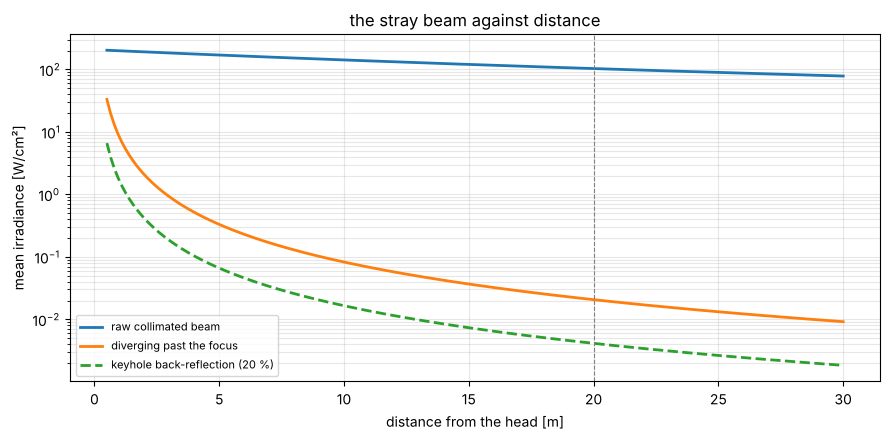

In [3]:
BEAMS = si.stray_beams(POWER)
display(pd.DataFrame({b.name: {"power [W]": b.power, "radius at 20 m [mm]": b.radius * 1e3, "mean irradiance [W/cm²]": b.mean_irradiance / 1e4, "note": b.note} for b in BEAMS}).T)
fig, ax = plt.subplots(figsize=(9, 4.5)); sid.stray_view(BEAMS, si.HEAD, si.DELIVERY, POWER, ax=ax)
plt.tight_layout(); plt.savefig(OUT / "stray.png", dpi=110); plt.show()

## 2. The barriers and the screening

Per barrier and beam: the absorbed irradiance, the transmitted share, the semi-infinite time to surface damage, the lumped
lower bound on burn-through, the thin-plate upper bound on the steady rise, and where neither bound decides, the steady
solve's hottest point — then the decision: fails (transparent), survives (which bound), or simulate.

In [4]:
SCR = pd.DataFrame([si.screen(b, beam) for b in si.BARRIERS for beam in BEAMS])
display(SCR[SCR["beam"] == "raw collimated beam"].set_index("barrier")[["absorbed_irradiance_W_per_cm2", "transmitted_fraction", "t_surface_damage_bound", "t_burn_through_lower_bound",
                                                                         "steady_rise_bound_K", "damage_rise_K", "steady_T_max", "decision"]].round(3))
print("decisions over all beams:", SCR["decision"].value_counts().to_dict())

,absorbed_irradiance_W_per_cm2,transmitted_fraction,t_surface_damage_bound,t_burn_through_lower_bound,steady_rise_bound_K,damage_rise_K,steady_T_max,decision
barrier,,,,,,,,
black polycarbonate 5 mm,97.651,0.000,0.047,12.495,346641.176,426.85,10017.872,simulate
black polycarbonate 10 mm,97.651,0.000,0.047,24.990,173320.588,426.85,9202.466,simulate
clear polycarbonate 5 mm,94.567,0.817,0.050,12.902,335694.613,426.85,NaN,fails: transparent
clear polycarbonate 10 mm,94.567,0.739,0.050,25.805,167847.306,426.85,NaN,fails: transparent
laser-safety polycarbonate 5 mm,94.567,0.000,0.050,12.902,335694.613,426.85,9779.868,simulate
laser-safety polycarbonate 10 mm,94.567,0.000,0.050,25.805,167847.306,426.85,8924.841,simulate
fired clay brick 65 mm,77.093,0.000,2.285,221.604,20532.056,1156.85,11957.275,simulate
aluminium 1.5 mm,12.335,0.000,10841.678,32.993,153.252,639.85,NaN,survives: steady bound
aluminium 3 mm,12.335,0.000,10841.678,65.987,76.626,639.85,NaN,survives: steady bound


decisions over all beams: {'survives: steady bound': 11, 'survives: energy bound': 10, 'fails: transparent': 6, 'simulate': 5, 'survives: steady solve': 1}


## 3. The simulations that decide, and the verdict

The transient runs only for the pairs the screening left: the beam's real profile on the plate, enthalpy with the latent
heats, ablation of the cells that reach the decomposition point, convection and radiation; it stops at burn-through or
when the front stalls. Then the verdict per class, the worst beam deciding each barrier.

33 pairs screened, 5 simulated in 39 s


,holds [s],surface damage [s],T1 10 s,T2 100 s,T3 30000 s,decided by
barrier,,,,,,
black polycarbonate 5 mm,13.12,0.25,True,False,False,simulation: ablated through at the centre
black polycarbonate 10 mm,26.49,0.50,True,False,False,simulation: ablated through at the centre
clear polycarbonate 5 mm,0.00,0.05,False,False,False,fails: transparent
clear polycarbonate 10 mm,0.00,0.05,False,False,False,fails: transparent
laser-safety polycarbonate 5 mm,13.68,0.26,True,False,False,simulation: ablated through at the centre
laser-safety polycarbonate 10 mm,27.35,0.52,True,False,False,simulation: ablated through at the centre
fired clay brick 65 mm,inf,29.14,True,True,True,simulation: steady
aluminium 1.5 mm,inf,10841.68,True,True,True,survives: steady bound
aluminium 3 mm,inf,10841.68,True,True,True,survives: steady bound


,holds_s,source,T1,T2,T3,worst_beam
black polycarbonate 5 mm,13.119647,simulation: ablated through at the centre,True,False,False,raw collimated beam
black polycarbonate 10 mm,26.489193,simulation: ablated through at the centre,True,False,False,raw collimated beam
clear polycarbonate 5 mm,0.0,fails: transparent,False,False,False,raw collimated beam
clear polycarbonate 10 mm,0.0,fails: transparent,False,False,False,raw collimated beam
laser-safety polycarbonate 5 mm,13.676485,simulation: ablated through at the centre,True,False,False,raw collimated beam
laser-safety polycarbonate 10 mm,27.352971,simulation: ablated through at the centre,True,False,False,raw collimated beam
fired clay brick 65 mm,inf,simulation: steady,True,True,True,raw collimated beam
aluminium 1.5 mm,inf,survives: steady bound,True,True,True,raw collimated beam
aluminium 3 mm,inf,survives: steady bound,True,True,True,raw collimated beam
mild steel 1.5 mm,inf,survives: steady solve,True,True,True,raw collimated beam


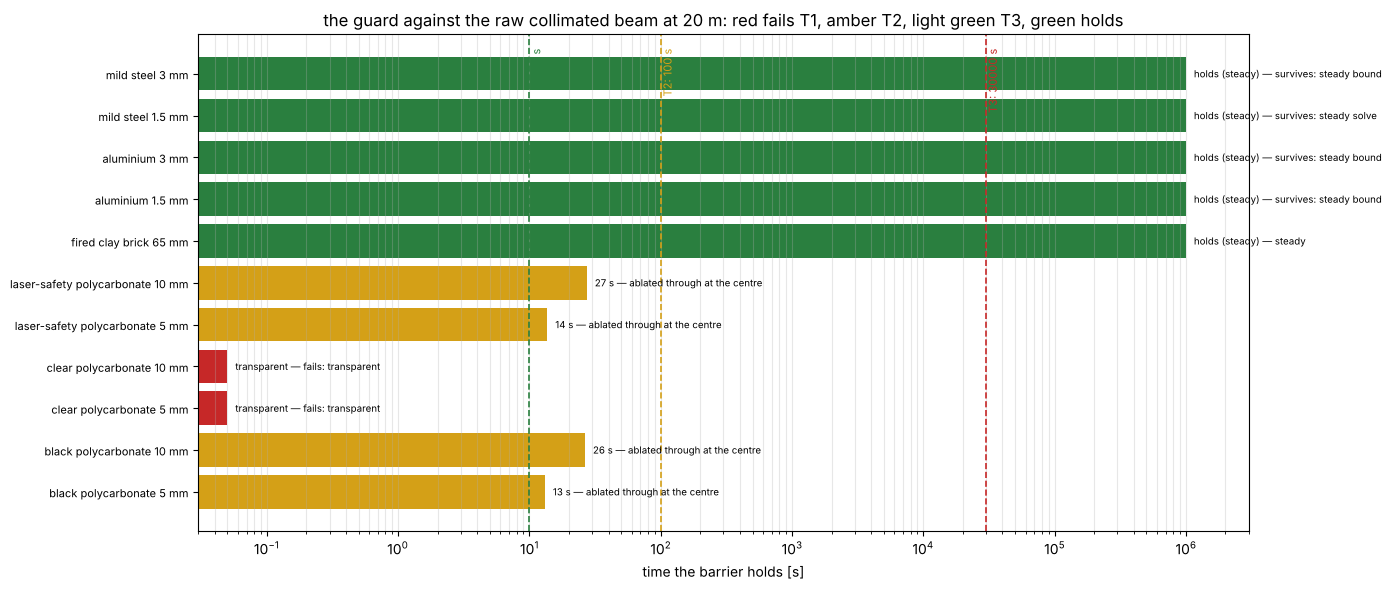

In [5]:
t0 = time.time()
G = si.guard_study(POWER)
print(f"{len(G['rows'])} pairs screened, {sum(r['simulated'] for r in G['rows'])} simulated in {time.time() - t0:.0f} s")
VER = pd.DataFrame([{"barrier": r["barrier"], "beam": r["beam"], "holds [s]": r["holds_s"], "surface damage [s]": r["surface_damage_s"], "T1 10 s": r["T1"], "T2 100 s": r["T2"],
                     "T3 30000 s": r["T3"], "decided by": r["source"]} for r in G["rows"]])
display(VER[VER["beam"] == "raw collimated beam"].set_index("barrier").drop(columns="beam").round(2))
WORST = pd.DataFrame({b.name: {**{k: v for k, v in r["worst_for_barrier"].items() if k in ("holds_s", "T1", "T2", "T3", "worst_beam", "source")}}
                      for b, r in zip(si.BARRIERS, [row for row in G["rows"] if "worst_for_barrier" in row])}).T
display(WORST)
fig, ax = plt.subplots(figsize=(14, 6)); sid.guard_timeline(G["rows"], si.EXPOSURE, ax=ax)
plt.tight_layout(); plt.savefig(OUT / "verdict.png", dpi=110); plt.show()

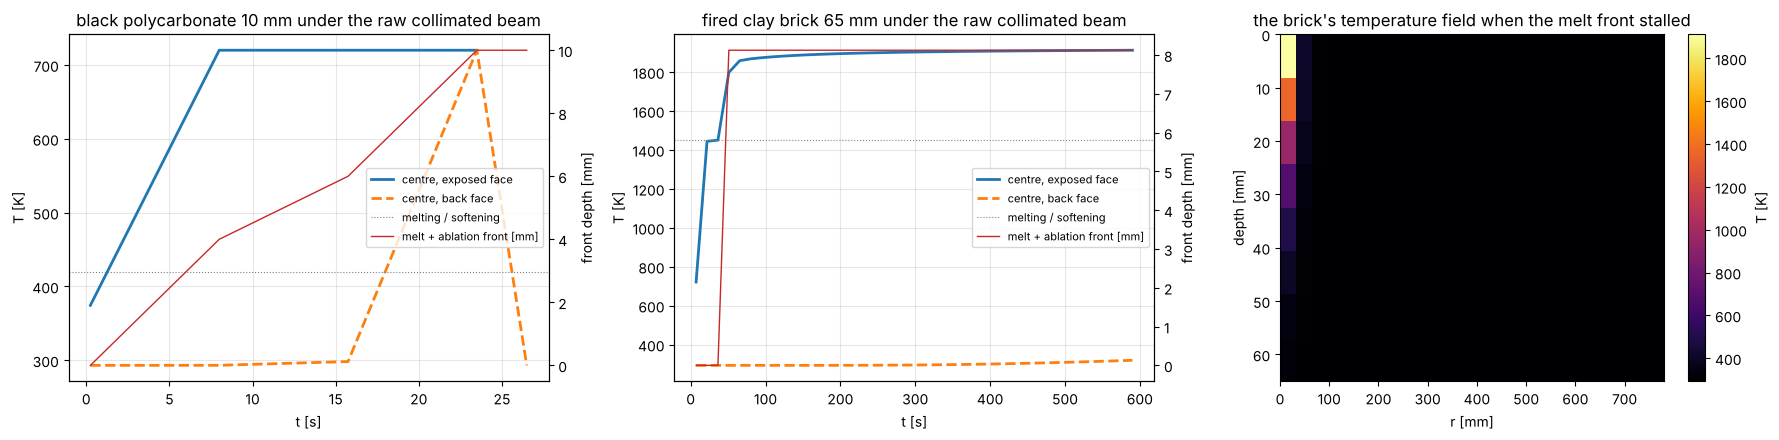

In [6]:
sims = list(G["simulations"].items())
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (key, sim) in zip(axs[:2], [s for s in sims if "polycarbonate 10" in s[0][0]][:1] + [s for s in sims if "brick" in s[0][0]][:1]):
    sid.transient_view(sim, ax=ax, title=f"{key[0]} under the {key[1]}")
brick = next((s for k, s in sims if "brick" in k[0]), None)
if brick is not None:
    sid.field_view(brick, ax=axs[2], title="the brick's temperature field when the melt front stalled")
plt.tight_layout(); plt.savefig(OUT / "transients.png", dpi=110); plt.show()

## 4. The collimated beam against distance — the reference sheet

The reference wall: a **2 mm polycarbonate sheet, 1200 kg/m³, 60 × 60 cm** (black, opaque at 1 µm; a clear one would
pass the beam at any distance), its edge the cold boundary. The raw collimated beam grows only by the process fibre's
divergence (r_core/f_collimator = 0.25 mrad): 12 mm at the head, 17 mm at 20 m, 37 mm at 100 m, 62 mm at 200 m — the
irradiance falls as 1/r², from 200 to 8 W/cm², but a kilowatt is a kilowatt and a 2 mm sheet has 2 mm of material to
give. At each distance: the screening, the transient on the sheet's own grid where the screening cannot decide, the time
it holds against T1/T2/T3.

,beam_radius_mm,irradiance_W_per_cm2,absorbed_W_per_cm2,decision,surface_damage_s,holds_s,T1,T2,T3,source
distance_m,,,,,,,,,,
10.0,14.5,141.29,134.23,simulate,0.07,3.78,False,False,False,simulation: ablated through at the centre
20.0,17.0,102.79,97.65,simulate,0.10,5.25,False,False,False,simulation: ablated through at the centre
50.0,24.5,49.49,47.02,simulate,0.21,11.21,True,False,False,simulation: ablated through at the centre
100.0,37.0,21.70,20.61,simulate,0.47,27.70,True,False,False,simulation: ablated through at the centre
200.0,62.0,7.73,7.34,simulate,1.83,110.06,True,True,False,simulation: ablated through at the centre


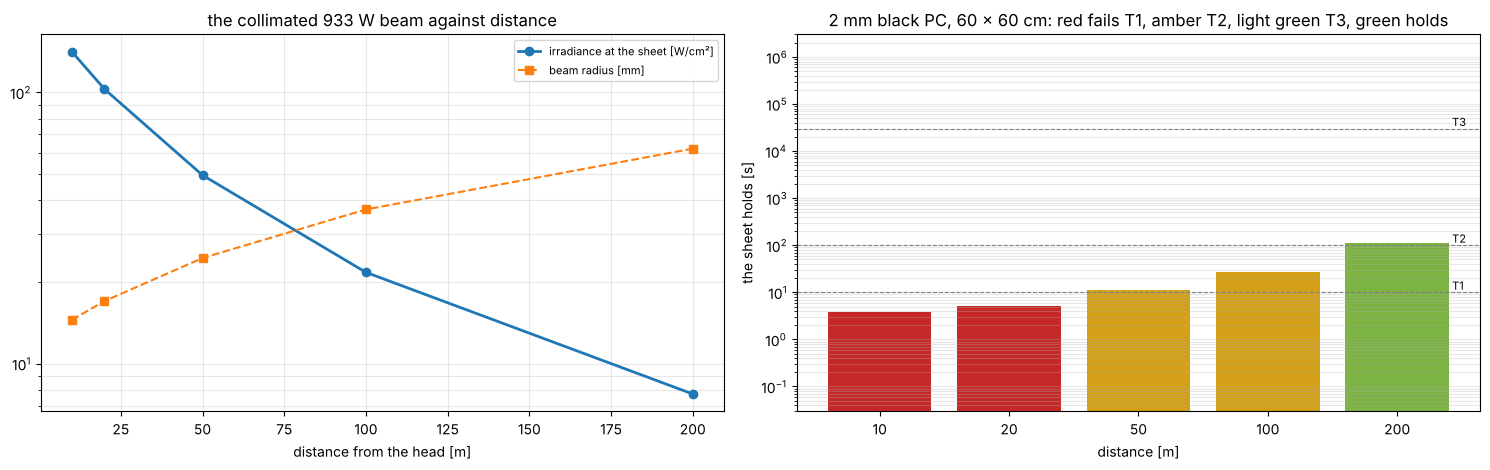

In [7]:
DIST = si.guard_vs_distance(POWER)
DT = pd.DataFrame([{k: v for k, v in r.items() if k != "simulation"} for r in DIST]).set_index("distance_m")
display(DT.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
axs[0].semilogy(DT.index, DT["irradiance_W_per_cm2"], "o-", lw=2, label="irradiance at the sheet [W/cm²]")
axs[0].semilogy(DT.index, DT["beam_radius_mm"], "s--", lw=1.5, label="beam radius [mm]")
axs[0].set_xlabel("distance from the head [m]"); axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3, which="both"); axs[0].set_title(f"the collimated {POWER:.0f} W beam against distance")
holds = np.array([min(h, 1e6) if h > 0 else 0.05 for h in DT["holds_s"]])
cols = ["#c62828" if not r["T1"] else ("#d4a017" if not r["T2"] else ("#7cb342" if not r["T3"] else "#2a7f3f")) for r in DIST]
axs[1].bar([str(int(d)) for d in DT.index], holds, color=cols)
for cls, t in si.EXPOSURE.items():
    axs[1].axhline(t, color="grey", ls="--", lw=0.8); axs[1].text(4.4, t, f" {cls}", fontsize=8, va="bottom")
axs[1].set_yscale("log"); axs[1].set_ylim(0.03, 3e6); axs[1].set_xlabel("distance [m]"); axs[1].set_ylabel("the sheet holds [s]")
axs[1].set_title("2 mm black PC, 60 × 60 cm: red fails T1, amber T2, light green T3, green holds"); axs[1].grid(alpha=0.3, axis="y", which="both")
plt.tight_layout(); plt.savefig(OUT / "distance.png", dpi=110); plt.show()

### What the air takes on the way

At 1070 nm the air's molecules take nothing over 200 m; aerosols do — by the Kruse–Kim law on the day's visibility — and
fog's droplets scatter regardless of wavelength. Four days: a clear day (40 km visibility), a wet day (8 km, more
vapour), a dusty town (4 km, absorbing particles), a foggy autumn morning (300 m). The power that arrives at the sheet
is the launched power times the transmission; the verdicts above are for a clear day — the worst case, as they should
be: fog is the only air that takes more than a few per cent, and nobody welds in it.

,visibility [km],loss [dB/km],arrives at 10 m [W],arrives at 20 m [W],arrives at 50 m [W],arrives at 100 m [W],arrives at 200 m [W],lost at 10 m [%],lost at 20 m [%],lost at 50 m [%],lost at 100 m [%],lost at 200 m [%]
clear day,40.0,0.22,932.78,932.30,930.87,928.49,923.75,0.05,0.10,0.26,0.51,1.02
wet day,8.0,1.02,931.06,928.86,922.31,911.50,890.25,0.24,0.47,1.17,2.33,4.61
dusty town,4.0,3.08,926.66,920.11,900.73,869.34,809.80,0.71,1.41,3.49,6.85,13.23
foggy autumn morning,0.3,56.63,819.16,719.01,486.23,253.33,68.76,12.23,22.96,47.90,72.86,92.63


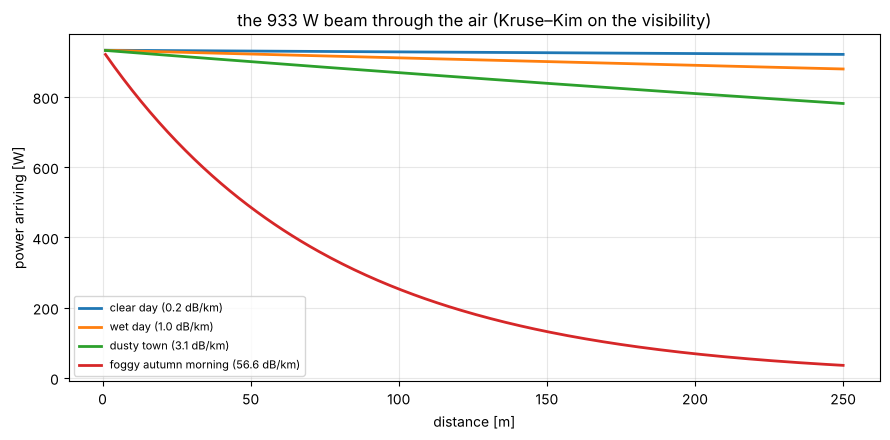

In [8]:
AIR = hy.transmission_table(si.DISTANCES, si.LAM)
AT = pd.DataFrame({name: {"visibility [km]": a["visibility_m"] / 1e3, "loss [dB/km]": a["db_per_km"], **{f"arrives at {int(d)} m [W]": POWER * t for d, t in a["transmission"].items()},
                          **{f"lost at {int(d)} m [%]": 100 * (1 - t) for d, t in a["transmission"].items()}} for name, a in AIR.items()}).T
display(AT.round(2))
fig, ax = plt.subplots(figsize=(9, 4.5))
dd = np.linspace(1, 250, 250)
for name, a in hy.ATMOSPHERES.items():
    ax.plot(dd, POWER * a.transmission(dd, si.LAM), lw=2, label=f"{name} ({a.loss_db_per_km(si.LAM):.1f} dB/km)")
ax.set_xlabel("distance [m]"); ax.set_ylabel("power arriving [W]"); ax.set_title(f"the {POWER:.0f} W beam through the air (Kruse–Kim on the visibility)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(OUT / "air.png", dpi=110); plt.show()

## 5. The same plates by finite elements — the fenix runs

Book **fenix** (`workflows/fenix/plate_thermal.py`) solves the same barriers under the same beam in FEniCSx, in its own
interpreter, one run directory per chapter like any CFD or FEA chapter: F1 `guard-steady` (every barrier's steady state,
Newton on the nonlinear radiation) and F2 `guard-ablation` (the transients the screening could not decide). This
notebook takes both runs as optional inputs; auto mode produces them in screening quality when they are missing and the
interpreter exists, and the table says NOT RUN otherwise. Below: the FEM numbers against the numpy solver's, case by case.

In [9]:
def fenix_run(key):
    """The gate holds the selected run's summary.json in ``inputs`` and its path in ``selections``."""
    return GATE.inputs.get(key), GATE.selections.get(key)
FX_STEADY, FX_STEADY_DIR = fenix_run("fenix/guard-steady@1kW")
FX_ABL, FX_ABL_DIR = fenix_run("fenix/guard-ablation@1kW")
rows = []
for b in si.BARRIERS:
    slug = b.name.replace(" ", "_").replace("-", "_").replace(".", "p")
    scr = next(r for r in G["rows"] if r["barrier"] == b.name and r["beam"] == "raw collimated beam")
    sim = G["simulations"].get((b.name, "raw collimated beam"))
    st = (FX_STEADY or {}).get("cases", {}).get(slug, {})
    ab = (FX_ABL or {}).get("cases", {}).get(slug, {})
    rows.append({"barrier": b.name, "numpy steady T_max [K]": scr["steady_T_max"], "FEM steady T_max [K]": st.get("T_max"),
                 "numpy burn-through [s]": sim.failure_time if sim is not None else math.nan, "FEM burn-through [s]": ab.get("failure_time") if ab else None,
                 "FEM status": (ab or st).get("status", "NOT RUN")})
FX = pd.DataFrame(rows).set_index("barrier"); display(FX.round(1))
FX_SHEET, FX_SHEET_DIR = fenix_run("fenix/sheet-distance@1kW")
if FX_SHEET:
    SH = pd.DataFrame({r["distance_m"]: {"numpy burn-through [s]": r["holds_s"], "FEM burn-through [s]": (FX_SHEET["cases"].get(f"pc2mm_at_{int(r['distance_m'])}m") or {}).get("failure_time"),
                                         "FEM status": (FX_SHEET["cases"].get(f"pc2mm_at_{int(r['distance_m'])}m") or {}).get("status", "NOT RUN")} for r in DIST}).T
    SH.index.name = "distance [m]"; print("the reference sheet (F3 sheet-distance):"); display(SH.round(1))
else:
    print("fenix/sheet-distance@1kW: NOT RUN")
print("fenix steady run:", FX_STEADY_DIR or "NOT RUN", "| ablation run:", FX_ABL_DIR or "NOT RUN",
      "|", (FX_ABL or FX_STEADY or {}).get("fenicsx", ""), "| quality", (FX_ABL or {}).get("quality", ""))

,numpy steady T_max [K],FEM steady T_max [K],numpy burn-through [s],FEM burn-through [s],FEM status
barrier,,,,,
black polycarbonate 5 mm,10017.9,2131.8,13.1,14.8,solved
black polycarbonate 10 mm,9202.5,2180.1,26.5,31.8,solved
clear polycarbonate 5 mm,NaN,2114.1,NaN,NaN,solved
clear polycarbonate 10 mm,NaN,2161.3,NaN,NaN,solved
laser-safety polycarbonate 5 mm,9779.9,2114.1,13.7,15.6,solved
laser-safety polycarbonate 10 mm,8924.8,2161.3,27.4,32.4,solved
fired clay brick 65 mm,11957.3,2394.9,NaN,NaN,solved
aluminium 1.5 mm,NaN,420.3,NaN,NaN,solved
aluminium 3 mm,NaN,359.6,NaN,NaN,solved


the reference sheet (F3 sheet-distance):


,numpy burn-through [s],FEM burn-through [s],FEM status
distance [m],,,
10.0,3.781502,4.25419,solved
20.0,5.247859,5.647696,solved
50.0,11.21117,12.197338,solved
100.0,27.70029,25.5695,solved
200.0,110.058728,73.125879,solved


fenix steady run: /home/user/vegeta/workflows/runs/fenix/guard-steady/20261017-162422_1kW_screening | ablation run: /home/user/vegeta/workflows/runs/fenix/guard-ablation/20261017-162526_1kW_screening | dolfinx 0.11.0 (/home/user/mm/fenicsx/bin/python) | quality screening


## 6. The record

In [10]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REPORT = {"meta": {"notebook": "49_svarog_guard", "power_W": POWER, "distance": si.DISTANCE, "exposure": si.EXPOSURE, "debug": DEBUG, "power_report": str(R48_PATH) if R48 else None},
          "beams": [vars(b) for b in BEAMS], "screening": SCR.to_dict(orient="records"),
          "verdicts": [{k: v for k, v in r.items()} for r in G["rows"]],
          "simulations": {f"{k[0]} | {k[1]}": s.to_dict() for k, s in G["simulations"].items()},
          "distance": DT.to_dict(orient="index"), "air": AT.to_dict(orient="index"),
          "fenix": {"steady_run": str(FX_STEADY_DIR) if FX_STEADY_DIR else None, "ablation_run": str(FX_ABL_DIR) if FX_ABL_DIR else None, "table": FX.to_dict(orient="index")}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "49_svarog_guard.json").write_text(json.dumps(REPORT, indent=1, default=_j))
print("written", DATA / "reports" / "49_svarog_guard.json")

written designs/data/reports/49_svarog_guard.json


In [11]:
STAMPS = GATE.leave()

## 7. Reading it

- **Clear polycarbonate is not a guard at 1 µm**: it passes ~80 %. The black and the dyed sheets are eaten through in
  12 s (5 mm) and 25 s (10 mm) by a 110 W/cm² beam: T1 only. A plastic panel for T2 needs to be thicker, or metal.
- **Metals hold by conduction**: aluminium absorbs 12 % and spreads it, steel 38 % and spreads it less — 1.5 mm steel runs
  at ~1250 K under the collimated beam and never melts (the steady solve), 3 mm stays cooler, aluminium colder still. All
  hold T3. Their uncertain number is the absorptivity: a painted or oxidised steel at 0.6–0.8 would be the case to re-run.
- **Brick melts at the surface in under a minute and then stalls**: at 2000 K it radiates more than it absorbs; the front
  stops 8 mm in. It holds T3 if the melt stays in the wall.
- **The diverging beams are harmless to every barrier**: the guard problem is the collimated beam, and the design answer
  is to make it impossible — interlock the lenses, cap the head — before asking the panel to take it.
- The ablation here is a cell-removal model on a coarse axisymmetric grid; the fenix runs are the same physics by finite
  elements (section 4): within 5 % on the steady states, 10–20 % on the burn-through times (the cell model's grid), the
  verdicts the same.